# Introduction

👋 Welcome to the practical sessions of the Generative AI course.

These tutorials complement the lectures by focusing on implementation. Each Friday session combines a pen-and-paper problem sheet, a short tour of the notebook, and time to work through the notebook.

## 🏫 Session Format

1. **Problem sheet (first hour, about 50 min)**: pen-and-paper exercises on the week's material, alone or in pairs. Written solutions are released on Scientia the following Monday.
2. **Break (10 min)**.
3. **Notebook tour (about 10 min)**: a few slides on how this notebook is organised and how it connects to the problem sheet.
4. **Notebook (until the end of the session)**: work through this notebook. Run the provided cells and change their parameters to see what happens. The exercises have code cells with `# TODO` comments and `None` placeholders for you to fill in. If you get stuck on an exercise, you can move on and come back to it later; Part 2 does not depend on Part 1. Raise your hand if you need help.

**Smart AI Use**: You have access to Imperial's AI tools via [dAIsy](https://www.imperial.ac.uk/admin-services/ict/training-and-resources/daisy/). Letting an AI write the exercise code for you defeats the purpose of the exercise. Treat it as a copilot instead: ask it about unfamiliar APIs, or use it to help debug errors you cannot solve on your own.

## 💻 Computational Environment

This notebook is deliberately small: it needs only PyTorch and matplotlib, downloads nothing, and runs in about a minute on a laptop CPU, so you do not need a GPU today. It also runs on Google Colab and on Apple-silicon Macs (the setup cell below picks the MPS backend automatically). If you already have a GPU set up from the logistics lecture (GPU Dojo, a lab workstation or the department cluster), you are welcome to use it; remember to stop a GPU Dojo VM when you finish, because its GPU-hour budget is used whenever it is running.

If `import torch` fails in the setup cell, run `%pip install torch matplotlib` in a new cell. On lab machines and the cluster, install into a virtual environment on `/vol/bitbucket/$USER` rather than your home directory, which is small.

## 🛠️ Jupyter Notebook Workflow

- Run a cell with **Shift + Enter**.
- Run the cells **in order, from the top**. The setup cell below defines `device` and `SEED`, which every Part uses. Section 2.3 uses your `rnn_forward` from Exercise 2.2 once it matches `nn.RNN`. Part 3 uses the data function from Section 2.3 and your LSTM from Exercise 3.1 (Sections 3.2 and 3.3 train and plot only the vanilla RNN until Exercise 3.1 is complete). Part 1 needs only the setup cell.

Run the cell below to check your environment.

In [1]:
import os
import shutil
import subprocess

import torch

print(f"PyTorch version: {torch.__version__}")

# The equivalent of `!nvidia-smi`, which does not fail on machines without an NVIDIA driver
if shutil.which("nvidia-smi"):
    print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
else:
    print("nvidia-smi not found: this machine has no NVIDIA driver.")

# Device: CUDA, then Apple MPS, then CPU. Set the environment variable T1_DEVICE (e.g. "cpu") to override.
if os.environ.get("T1_DEVICE"):
    device = torch.device(os.environ["T1_DEVICE"])
elif torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

if device.type == "cuda":
    print(f"✅ Using GPU: {torch.cuda.get_device_name(0)}")
elif device.type == "mps":
    print("✅ Using the Apple-silicon GPU (MPS).")
else:
    print("⚠️ Using the CPU. This notebook still runs, but on a GPU machine it means PyTorch cannot see the GPU.")

# Full float32 precision on NVIDIA GPUs, for the exact comparisons in Exercises 1.2 and 2.2
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

SEED = 0
torch.manual_seed(SEED)  # seeds the random number generators of all devices
print(f"Global seed: {SEED}")

PyTorch version: 2.8.0
nvidia-smi not found: this machine has no NVIDIA driver.
⚠️ Using the CPU. This notebook still runs, but on a GPU machine it means PyTorch cannot see the GPU.
Global seed: 0


# Tutorial 1: Deep Learning Basics (CNNs and RNNs)

In this notebook we implement the two architectures from the lecture and the problem sheet. Part 1 builds the convolution and max-pooling layers from the problem sheet in PyTorch and implements a convolution layer from scratch. Part 2 implements the lecture's recurrent neural network (RNN), unfolded over time, and a training step for it. Part 3 implements the lecture's LSTM cell, compares a vanilla RNN with the LSTM on a task that needs memory over many steps, and looks at the gradient flow through the unfolded network.

By the end of this session you will be able to:
- check the output sizes and parameter counts of convolution and pooling layers in PyTorch, and implement a multi-channel convolution that matches `F.conv2d`;
- implement $h_t = \tanh W \begin{pmatrix} x_t \\ h_{t-1} \end{pmatrix}$ and the unfolded forward pass, reproduce `nn.RNN` exactly, and write a gradient-descent training step;
- implement the lecture's LSTM cell;
- see the vanishing-gradient problem of vanilla RNNs, and how the LSTM's memory cell avoids it.

The reading list is on the lecture's "Reading Materials and Reference" slide.

## Part 1: Convolutional Neural Networks

- **Sizes and parameters**: build the convolution and pooling layers from the problem sheet and check your answers.
- **From scratch**: implement a multi-channel convolution and reproduce `F.conv2d` exactly.
- **Max-pooling**: implement max-pooling from scratch and reproduce `F.max_pool2d`.
- **Training**: train a tiny CNN on synthetic images.

### **1.1 Exercise: The Layers from the Problem Sheet**

In this exercise you create the convolution layer and the max-pooling layer from the CNN question of the problem sheet with PyTorch layers, and check your answers for their output sizes and parameter counts.

**Scenario**:
As in the lecture, a feature map is $C \times H \times W$, and PyTorch adds a batch dimension in front: a batch of images is $N \times C \times H \times W$, so the sheet's $4 \times 31 \times 31$ input is a `(1, 4, 31, 31)` tensor. A convolution layer's weight is $C_{\text{out}} \times C_{\text{in}} \times K \times K$, with one bias per filter (lecture p.42).

**Requirements**:

Create the convolution layer `conv` and the max-pooling layer `pool` from the problem sheet's CNN question (Q3) with `nn.Conv2d` and `nn.MaxPool2d`, reading their settings from the sheet. PyTorch's `padding` is the number of zeros added on **each** side, like $P$ in the lecture (p.42).

The provided code passes a random input through the two layers and prints each output shape and each layer's number of parameters. Compare them with your answers on the sheet.

In [2]:
import torch.nn as nn

torch.manual_seed(SEED)
# TODO: create conv, the convolution layer, and pool, the max-pooling layer, of the problem sheet's CNN question (Q3)
conv = nn.Conv2d(4, 10, kernel_size=3, stride=2, padding=1)
pool = nn.MaxPool2d(kernel_size=2, stride=2)

# --- Shapes and parameter counts (Implemented) ---
print("-" * 30)
if conv is None or pool is None:
    print("Please complete the TODO sections to see the shapes and parameter counts.")
else:
    conv, pool = conv.to(device), pool.to(device)
    x = torch.randn(1, 4, 31, 31, device=device)  # N x C x H x W: one 4 x 31 x 31 input
    print(f"{'input':12s} {str(tuple(x.shape)):16s}")
    x = conv(x)
    print(f"{'convolution':12s} {str(tuple(x.shape)):16s} parameters {sum(p.numel() for p in conv.parameters())}")
    x = pool(x)
    print(f"{'max-pooling':12s} {str(tuple(x.shape)):16s} parameters {sum(p.numel() for p in pool.parameters())}")

------------------------------
input        (1, 4, 31, 31)  
convolution  (1, 10, 16, 16)  parameters 370
max-pooling  (1, 10, 8, 8)    parameters 0


### **1.2 Exercise: A Convolution from Scratch**

In this exercise you implement the forward pass of a 2-D convolution layer and check it against PyTorch.

**Scenario**:
`my_conv2d(x, weight, bias, stride, padding)` should compute exactly what `F.conv2d` computes for a batch of multi-channel images. Each filter slides over the padded input; at every position we multiply element-wise, sum over all input channels and the window, and add the filter's bias (lecture p.37 and p.41-42):

$$\text{out}[n, o, i, j] = b_o + \sum_{c=0}^{C_{\text{in}}-1} \sum_{u=0}^{K-1} \sum_{v=0}^{K-1} \text{weight}[o, c, u, v]\; x_{\text{pad}}[n, c, iS + u, jS + v],$$

with indices starting at 0 and $x_{\text{pad}}$ the input with $P$ zeros added on each side of both spatial dimensions.

**Requirements**:

1. **Inputs**: `x` of shape `(N, C_in, H, W)`, `weight` of shape `(C_out, C_in, kernel_size, kernel_size)`, `bias` of shape `(C_out,)`, and integers `stride` ($S$) and `padding` ($P$). In the code, `kernel_size` is $K$ in the lecture.
2. **Padding (TODO 1)**: zero-pad `x` by `padding` on each side of the height and width dimensions (not the batch or channel dimensions), giving `x_pad` of shape `(N, C_in, H + 2*padding, W + 2*padding)`.
3. **Output size (TODO 2)**: `H_out` and `W_out`, the output height and width from the lecture's output-size formula (p.42). They must be integers; all sizes in this notebook divide exactly. Height and width can differ.
4. **Output (TODO 3)**: the output tensor `out` of shape `(N, C_out, H_out, W_out)` is provided. Loop over all output positions $(i, j)$. For each, take the window of the padded input that output position $(i, j)$ sees, given the stride and the kernel size (for all images and all input channels at once), multiply it element-wise with every filter, sum over the input channels and the window, add the bias, and store the result, of shape `(N, C_out)`, at position $(i, j)$ of `out`.

The verification code compares your function with `F.conv2d` on two test cases: the convolution layer of Section 1.1 on a batch of two inputs, and a non-square input of size $4 \times 11 \times 8$ with 5 filters, $K = 3$, padding 2 and stride 3.

**Hint**: useful functions are `F.pad` (look up in its documentation how it orders the padding sizes) and either `torch.einsum` or broadcasting followed by `.sum` over several dimensions. An error about a size of 0 usually means that `H_out` or `W_out` is wrong.

In [3]:
import torch.nn.functional as F


def my_conv2d(x, weight, bias, stride=1, padding=0):
    """2-D convolution as computed by F.conv2d: x (N, C_in, H, W), weight (C_out, C_in, kernel_size, kernel_size), bias (C_out,)."""
    N, C_in, H, W = x.shape
    C_out, _, kernel_size, _ = weight.shape  # kernel_size is K in the lecture

    # TODO 1: zero-pad x by `padding` on each side of the height and width
    #         -> x_pad of shape (N, C_in, H + 2*padding, W + 2*padding)
    x_pad = F.pad(x, (padding, padding, padding, padding))

    # TODO 2: the output height and width from the lecture's output-size formula (p.42); they must be integers
    H_out = (H - kernel_size + 2 * padding) // stride + 1
    W_out = (W - kernel_size + 2 * padding) // stride + 1

    if x_pad is None or H_out is None:  # TODO 1 or TODO 2 not done yet
        return None
    out = torch.zeros(N, C_out, H_out, W_out, device=x.device, dtype=x.dtype)

    # TODO 3: loop over all output positions (i, j); for each, take the window of the padded input that
    #         output position (i, j) sees, given the stride and kernel size; multiply it with every filter,
    #         sum over the input channels and the window, add the bias, and store the result,
    #         of shape (N, C_out), at position (i, j) of out
    for i in range(H_out):
        for j in range(W_out):
            window = x_pad[:, :, i * stride : i * stride + kernel_size, j * stride : j * stride + kernel_size]
            out[:, :, i, j] = torch.einsum("ncuv,ocuv->no", window, weight) + bias  # (N, C_out)
    return out


# --- Verification Code (Implemented) ---
print("-" * 30)
torch.manual_seed(SEED)
tests = {  # name: (x, weight, bias, stride, padding)
    "sizes of Section 1.1": (torch.randn(2, 4, 31, 31, device=device), torch.randn(10, 4, 3, 3, device=device),
                             torch.randn(10, device=device), 2, 1),
    "non-square, padding=2, stride=3": (torch.randn(2, 4, 11, 8, device=device), torch.randn(5, 4, 3, 3, device=device),
                                        torch.randn(5, device=device), 3, 2),
}
for name, (x, weight, bias, stride, padding) in tests.items():
    mine = my_conv2d(x, weight, bias, stride=stride, padding=padding)
    if mine is None:
        print("Please complete the TODO sections to run the verification "
              "(if you have written the loops, remove the placeholder line `return None`).")
        break
    ref = F.conv2d(x, weight, bias, stride=stride, padding=padding)
    # atol=1e-4 allows for rounding differences between our sums and PyTorch's convolution kernels
    # (different summation orders); a real mistake (e.g. a wrong window or a missing bias) gives errors of 0.1 or more, far above 1e-4
    match = mine.shape == ref.shape and torch.allclose(mine, ref, atol=1e-4)
    print(f"{name}: yours {tuple(mine.shape)}, F.conv2d {tuple(ref.shape)}, match: {match}")
    if mine.shape == ref.shape and not match:
        print(f"    max absolute difference: {(mine - ref).abs().max().item():.3g}")

------------------------------
sizes of Section 1.1: yours (2, 10, 16, 16), F.conv2d (2, 10, 16, 16), match: True
non-square, padding=2, stride=3: yours (2, 5, 5, 4), F.conv2d (2, 5, 5, 4), match: True


### **1.3 Exercise: Max-Pooling from Scratch**

Max-pooling slides a window over each channel separately and keeps the largest value in each window (lecture p.41). It has no weights.

**Requirements**: complete `my_maxpool2d(x, kernel_size, stride)` for `x` of shape `(N, C, H, W)`, without padding.

1. **Output size (TODO 1)**: `H_out` and `W_out`, the output height and width from the lecture's output-size formula (p.42) with no padding, as on the problem sheet. They must be integers.
2. **Output (TODO 2)**: `out` of shape `(N, C, H_out, W_out)` is provided. Loop over all output positions $(i, j)$. For each, take the window of `x` that output position $(i, j)$ sees, given the stride and the kernel size (for all images and channels at once), take its maximum, of shape `(N, C)`, and store it at position $(i, j)$ of `out`.

The verification code compares your function with `F.max_pool2d` on the output of the convolution layer of Section 1.1 and on a $3 \times 6 \times 4$ input.

**Hint**: a useful tensor method is `amax`, which takes the maximum over several dimensions. An error about a size of 0 usually means that `H_out` or `W_out` is wrong.

In [4]:
import torch.nn.functional as F


def my_maxpool2d(x, kernel_size=2, stride=2):
    """Max-pooling of x (N, C, H, W) over kernel_size x kernel_size windows, each channel separately, no padding."""
    N, C, H, W = x.shape

    # TODO 1: the output height and width from the lecture's output-size formula (p.42) with no padding; they must be integers
    H_out = (H - kernel_size) // stride + 1
    W_out = (W - kernel_size) // stride + 1

    if H_out is None:  # TODO 1 not done yet
        return None
    out = torch.zeros(N, C, H_out, W_out, device=x.device, dtype=x.dtype)

    # TODO 2: loop over all output positions (i, j); for each, take the window of x that output position (i, j)
    #         sees, given the stride and kernel size, take its maximum, of shape (N, C), and store it at position (i, j) of out
    for i in range(H_out):
        for j in range(W_out):
            window = x[:, :, i * stride : i * stride + kernel_size, j * stride : j * stride + kernel_size]
            out[:, :, i, j] = window.amax(dim=(2, 3))  # (N, C)
    return out


# --- Verification Code (Implemented) ---
print("-" * 30)
torch.manual_seed(SEED)
for name, x in {"sizes of Section 1.1": torch.randn(2, 10, 16, 16, device=device),
                "3 x 6 x 4 input": torch.randn(1, 3, 6, 4, device=device)}.items():
    mine = my_maxpool2d(x, kernel_size=2, stride=2)
    if mine is None:
        print("Please complete the TODO sections to run the verification "
              "(if you have written the loops, remove the placeholder line `return None`).")
        break
    ref = F.max_pool2d(x, kernel_size=2, stride=2)
    match = mine.shape == ref.shape and torch.equal(mine, ref)  # taking a maximum involves no rounding
    print(f"{name}: yours {tuple(mine.shape)}, F.max_pool2d {tuple(ref.shape)}, match: {match}")
    if mine.shape == ref.shape and not match:
        print(f"    max absolute difference: {(mine - ref).abs().max().item():.3g}")

------------------------------
sizes of Section 1.1: yours (2, 10, 8, 8), F.max_pool2d (2, 10, 8, 8), match: True
3 x 6 x 4 input: yours (1, 3, 3, 2), F.max_pool2d (1, 3, 3, 2), match: True


### **1.4 Training a Tiny CNN**

To see a CNN learn, we train one on synthetic $1 \times 16 \times 16$ greyscale images, generated in code. Each image contains a horizontal line, a vertical line or a cross (both lines, crossing at their centres) of length 7 at a random position, plus Gaussian noise with standard deviation 0.3. The task is to predict which of the three classes it is, so guessing gives about 33 % accuracy.

The network is two blocks of a $3 \times 3$ convolution, ReLU and $2 \times 2$ max-pooling, followed by a fully-connected layer that outputs one score per class. It is trained with the cross-entropy loss for 300 steps, and the accuracy is measured on 1,000 new test images.

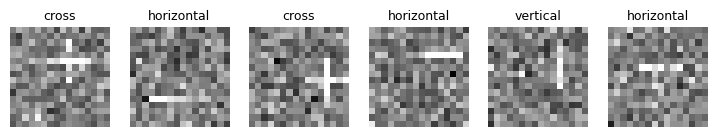

In [5]:
import matplotlib.pyplot as plt

CLASSES = ["horizontal", "vertical", "cross"]


def make_images(n, size=16, length=7, noise=0.3, generator=None):
    """n noisy images (n, 1, size, size) with a horizontal line, a vertical line or a cross, and their labels (n,)."""
    labels = torch.randint(0, 3, (n,), generator=generator)
    images = noise * torch.randn(n, 1, size, size, generator=generator)
    corners = torch.randint(0, size - length + 1, (n, 2), generator=generator)  # top-left corner of the line's box
    for k in range(n):
        r, c = corners[k].tolist()
        mid = length // 2
        if labels[k] != 1:  # horizontal line (classes 0 and 2)
            images[k, 0, r + mid, c : c + length] += 1.0
        if labels[k] != 0:  # vertical line (classes 1 and 2)
            images[k, 0, r : r + length, c + mid] += 1.0
    return images, labels


g = torch.Generator().manual_seed(SEED)
X_img_train, y_img_train = make_images(2000, generator=g)
X_img_test, y_img_test = make_images(1000, generator=g)

fig, axes = plt.subplots(1, 6, figsize=(9, 1.8))
for ax, img, label in zip(axes, X_img_train, y_img_train):
    ax.imshow(img[0], cmap="gray", vmin=-1, vmax=1)  # the same grey scale for every image
    ax.set_title(CLASSES[label], fontsize=9)
    ax.axis("off")
plt.show()

In [6]:
import time

import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(SEED)
tiny_cnn = nn.Sequential(
    nn.Conv2d(1, 8, kernel_size=3, padding=1),  # (N, 8, 16, 16)
    nn.ReLU(),
    nn.MaxPool2d(2),  # (N, 8, 8, 8)
    nn.Conv2d(8, 16, kernel_size=3, padding=1),  # (N, 16, 8, 8)
    nn.ReLU(),
    nn.MaxPool2d(2),  # (N, 16, 4, 4)
    nn.Flatten(),  # (N, 256)
    nn.Linear(16 * 4 * 4, 3),  # (N, 3) class scores
).to(device)
optimizer = torch.optim.Adam(tiny_cnn.parameters(), lr=3e-3)  # Adam: a variant of gradient descent not covered in the lecture; lr is the learning rate eta
X_tr, y_tr = X_img_train.to(device), y_img_train.to(device)
X_te, y_te = X_img_test.to(device), y_img_test.to(device)


@torch.no_grad()
def test_accuracy():
    return (tiny_cnn(X_te).argmax(dim=1) == y_te).float().mean().item()


print(f"Parameters: {sum(p.numel() for p in tiny_cnn.parameters()):,}")
print(f"step   0 | test accuracy {test_accuracy():.3f}")
start = time.time()
for step in range(1, 301):
    idx = torch.randint(0, len(X_tr), (64,), device=device)  # a random batch of 64 images
    loss = F.cross_entropy(tiny_cnn(X_tr[idx]), y_tr[idx])
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if step % 50 == 0:
        print(f"step {step:3d} | loss {loss.item():.3f} | test accuracy {test_accuracy():.3f} | {time.time() - start:.1f} s")

Parameters: 2,019
step   0 | test accuracy 0.378


step  50 | loss 0.613 | test accuracy 0.849 | 0.2 s
step 100 | loss 0.111 | test accuracy 0.987 | 0.4 s


step 150 | loss 0.034 | test accuracy 0.994 | 0.5 s
step 200 | loss 0.026 | test accuracy 0.997 | 0.7 s


step 250 | loss 0.008 | test accuracy 0.996 | 0.8 s
step 300 | loss 0.005 | test accuracy 0.998 | 1.0 s


In our run the test accuracy rises from 0.378 before training (guessing gives about 0.33) to 0.998 after 300 steps, in a few seconds on a laptop CPU, with 2,019 parameters. With six different seeds the final test accuracy was between 0.989 and 0.999. Because the same $3 \times 3$ filters are applied at every position (weight sharing), the convolution layers have only 80 and 1,168 parameters; the final fully-connected layer has 771.

If you want to experiment, pass `noise=1.0` (or a shorter `length`) to both `make_images(...)` calls in the cell that generates the images, re-run it and the training cell, and see how the accuracy changes.

## Part 2: The RNN Cell from the Lecture

- **The cell**: $h_t = \tanh W \begin{pmatrix} x_t \\ h_{t-1} \end{pmatrix}$, $y_t = F(h_t)$, $C_t = \text{Loss}(y_t, \text{GT}_t)$, and how `nn.RNN` stores $W$.
- **From scratch**: implement the unfolded forward pass, and reproduce `nn.RNN` exactly.
- **Training**: write one training step and train your RNN on a short sequence task.

### **2.1 From the Lecture to PyTorch**

The lecture's RNN cell takes the input $x_t \in \mathbb{R}^d$ and the previous hidden state $h_{t-1} \in \mathbb{R}^h$, stacks them into one vector of length $d + h$, and multiplies it by a single weight matrix $W \in \mathbb{R}^{h \times (d + h)}$:

$$h_t = \tanh W \begin{pmatrix} x_t \\ h_{t-1} \end{pmatrix}, \qquad y_t = F(h_t), \qquad C_t = \text{Loss}(y_t, \text{GT}_t).$$

Unfolding the RNN over $T$ steps applies the same cell, with the same $W$, at every step, starting from $h_0$. Here $F$ is a linear layer, $y_t = W_y h_t + b_y$ (the "Linear Classifier" on $h_t$ in the lecture's image-captioning example).

Splitting $W = [\,W_x \;\; W_h\,]$ into the $h \times d$ block that multiplies $x_t$ and the $h \times h$ block that multiplies $h_{t-1}$ gives $W \begin{pmatrix} x_t \\ h_{t-1} \end{pmatrix} = W_x x_t + W_h h_{t-1}$. `nn.RNN(d, h, bias=False)` stores exactly these two blocks, as `weight_ih_l0` ($W_x$) and `weight_hh_l0` ($W_h$).

In PyTorch a batch of $B$ examples is stored as rows: $x_t$ is a `(B, d)` tensor and $h_{t-1}$ a `(B, h)` tensor. Stacking them for every example joins them along the feature dimension into a `(B, d + h)` tensor, and applying $W$ to every row (a row vector $r$ becomes $r W^\top$) gives a `(B, h)` tensor.

| Tensor | Shape | Meaning |
|---|---|---|
| `x` | `(B, T, d)` | the inputs $x_1, \dots, x_T$ of $B$ sequences |
| `W` | `(h, d + h)` | the lecture's $W = [\,W_x \;\; W_h\,]$ |
| all hidden states | `(B, T, h)` | $h_1, \dots, h_T$ |
| `y` | `(B, T, q)` | $y_1, \dots, y_T$ |

The cell below uses $d = 16$ and $h = 32$ from the problem sheet, and $q = 10$ outputs, so you can check your answers.

In [7]:
import torch.nn as nn

d, h = 16, 32
# PyTorch's default nn.RNN(d, h) also adds two bias vectors inside the tanh (bias_ih_l0 and bias_hh_l0);
# the lecture's cell has no bias, so we switch them off with bias=False.
rnn = nn.RNN(d, h, bias=False, batch_first=True).to(device)
for name, p in rnn.named_parameters():
    print(f"{name:12s} {tuple(p.shape)}")

W = torch.cat([rnn.weight_ih_l0, rnn.weight_hh_l0], dim=1)  # W = [W_x W_h]
print(f"\nW = [W_x W_h]: {tuple(W.shape)}")
print(f"nn.RNN parameters: {sum(p.numel() for p in rnn.parameters())} = h * (d + h) = {h * (d + h)}")

q = 10
F_out = nn.Linear(h, q).to(device)  # the output layer y_t = F(h_t) = W_y h_t + b_y
print(f"output layer F: W_y {tuple(F_out.weight.shape)}, b_y {tuple(F_out.bias.shape)}, "
      f"{sum(p.numel() for p in F_out.parameters())} parameters")

weight_ih_l0 (32, 16)
weight_hh_l0 (32, 32)

W = [W_x W_h]: (32, 48)
nn.RNN parameters: 1536 = h * (d + h) = 1536
output layer F: W_y (10, 32), b_y (10,), 330 parameters


### **2.2 Exercise: The Unfolded RNN**

In this exercise you implement the lecture's RNN, unfolded over time (lecture p.53-54), and check that it computes exactly what `nn.RNN` computes.

**Scenario**:
`rnn_forward(x, W, W_y, b_y)` runs the unfolded RNN over a batch of sequences: at every step it stacks $x_t$ and $h_{t-1}$, applies the cell, and computes the output $y_t$, always with the same $W$, $W_y$ and $b_y$.

**Requirements**:

1. **Inputs**: `x` of shape `(B, T, d)`, `W` of shape `(h, d + h)`, `W_y` of shape `(q, h)` and `b_y` of shape `(q,)`. The initial hidden state $h_0 = 0$ and the empty lists `hs` and `ys` are provided.
2. **Loop over time (TODO)**: for every time step $t$:
    - stack the input at step $t$ (shape `(B, d)`) and the previous hidden state (shape `(B, h)`) into $\begin{pmatrix} x_t \\ h_{t-1} \end{pmatrix}$ for every sequence, a `(B, d + h)` tensor;
    - compute $h_t = \tanh W \begin{pmatrix} x_t \\ h_{t-1} \end{pmatrix}$ for every row (see the row form in Section 2.1), a `(B, h)` tensor, and keep it in `h` for the next step;
    - compute $y_t = W_y h_t + b_y$ for every row, a `(B, q)` tensor;
    - append $h_t$ to `hs` and $y_t$ to `ys`.

The function returns all outputs `(B, T, q)` and all hidden states `(B, T, h)`. The verification code copies the weights of an `nn.RNN(16, 32, bias=False)` into $W$ and those of an `nn.Linear(32, 10)` into $W_y, b_y$ ($d = 16$ and $h = 32$ from the problem sheet, and $q = 10$ outputs), and compares both results.

**Hint**: useful functions are `torch.cat`, which joins tensors along a given dimension, and `torch.tanh`, the element-wise tanh.

In [8]:
import torch.nn as nn


def rnn_forward(x, W, W_y, b_y):
    """Unfolded RNN. x: (B, T, d), W: (h, d + h), W_y: (q, h), b_y: (q,).
    Returns all outputs y (B, T, q) and all hidden states (B, T, h)."""
    B, T, d = x.shape
    h = torch.zeros(B, W.shape[0], device=x.device, dtype=x.dtype)  # h_0 = 0
    ys, hs = [], []

    # TODO: for every time step t (lecture p.53-54):
    #   1) stack the input at step t (B, d) and the previous hidden state (B, h) into one (B, d + h) tensor
    #   2) h_t = tanh W [x_t; h_{t-1}] for every row -> shape (B, h); keep it in h for the next step
    #   3) y_t = W_y h_t + b_y for every row -> shape (B, q)
    #   4) append h_t to hs and y_t to ys
    for t in range(T):
        xh = torch.cat([x[:, t], h], dim=1)
        h = torch.tanh(xh @ W.T)
        y = h @ W_y.T + b_y
        hs.append(h)
        ys.append(y)

    if not ys:  # TODO not done yet
        return None, None
    return torch.stack(ys, dim=1), torch.stack(hs, dim=1)


# --- Verification Code (Implemented) ---
print("-" * 30)
torch.manual_seed(SEED)
d, h, q, B, T = 16, 32, 10, 3, 5
ref_rnn = nn.RNN(d, h, bias=False, batch_first=True).to(device)
ref_head = nn.Linear(h, q).to(device)  # F
W = torch.cat([ref_rnn.weight_ih_l0, ref_rnn.weight_hh_l0], dim=1).detach()  # W = [W_x W_h], (h, d + h)
x = torch.randn(B, T, d, device=device)

my_y, my_hs = rnn_forward(x, W, ref_head.weight.detach(), ref_head.bias.detach())
if my_y is None:
    print("Please complete the TODO sections to run the verification.")
else:
    ref_hs, _ = ref_rnn(x)  # all hidden states, h_0 = 0
    ref_y = ref_head(ref_hs)
    # atol=1e-4 allows for rounding differences between our loop and the kernels inside nn.RNN;
    # a real mistake (e.g. stacking in the wrong order) gives errors of 0.1 or more, far above 1e-4
    hs_match = my_hs.shape == ref_hs.shape and torch.allclose(my_hs, ref_hs, atol=1e-4)
    y_match = my_y.shape == ref_y.shape and torch.allclose(my_y, ref_y, atol=1e-4)
    print(f"hidden states: yours {tuple(my_hs.shape)}, nn.RNN {tuple(ref_hs.shape)}, match: {hs_match}")
    print(f"outputs y:     yours {tuple(my_y.shape)}, nn.Linear {tuple(ref_y.shape)}, match: {y_match}")
    if not (hs_match and y_match) and my_hs.shape == ref_hs.shape:
        print(f"    max absolute difference in the hidden states: {(my_hs - ref_hs).abs().max().item():.3g}")

------------------------------
hidden states: yours (3, 5, 32), nn.RNN (3, 5, 32), match: True
outputs y:     yours (3, 5, 10), nn.Linear (3, 5, 10), match: True


### **2.3 Exercise: Training Your RNN**

We now train your `rnn_forward` on a sequence task of the "multiple-single" kind from the lecture (p.50: many inputs, one output). Each input $x_t$ is one of 8 symbols, one-hot encoded ($d = 8$), and the target at the last step, $\text{GT}_T$, is the **first** symbol of the sequence. The RNN has to keep that symbol in its hidden state while it reads the remaining inputs. Only the last output is used: the loss is $C_T = \text{Loss}(y_T, \text{GT}_T)$, the cross-entropy, and guessing gives an accuracy of $1/8$. Here the sequences are short, $T = 5$.

The first cell below provides the data and the initial weights, and checks your `rnn_forward` against `nn.RNN` on a random input. If it does not match yet, this section uses a reference forward pass computed with `nn.RNN` instead, so that you can do this exercise independently. Re-run that cell after finishing Exercise 2.2 to train your own `rnn_forward`.

**Scenario**:
One step of gradient descent (lecture p.23-24): a forward pass, the loss, a backward pass that computes the gradients, and the update $\theta \leftarrow \theta - \eta \, \partial C_T / \partial \theta$ of every parameter $\theta$ with learning rate $\eta$. The backward pass runs through the unfolded network: as in the lecture (p.54), the unfolded network is treated as one big feed-forward network, and the gradients for the copies of $W$ at the different time steps are summed (backpropagation through time). The update is done by `torch.optim.SGD`, which implements exactly this gradient-descent step, here with $\eta = 1$. Before the update the gradient norm is clipped, the lecture's remedy for exploding gradients (p.55; provided).

**Requirements**: complete `train_step(forward, x, gt, W, W_y, b_y, optimizer)`, where `forward` is `rnn_forward` (or the reference), `x` has shape `(B, T, 8)` and `gt` shape `(B,)`.

1. **Forward pass (TODO 1)**: run your unfolded RNN (the function `forward` chosen above) on the batch to get the outputs $y_1, \dots, y_T$, of shape `(B, T, 8)`.
2. **Loss (TODO 2)**: $C_T = \text{Loss}(y_T, \text{GT}_T)$, the cross-entropy between the outputs at the last time step (shape `(B, 8)`) and the targets `gt`.
3. **Backward pass (TODO 3)**: set the gradients of all parameters to zero (otherwise PyTorch adds the new gradients to the old ones), then run the backward pass from the loss (lecture p.24, p.54).
4. **Update (TODO 4)**: one gradient-descent update of the parameters with the optimizer; then return the loss as a Python float.

**Hint**: useful are `F.cross_entropy`, the optimizer's methods `zero_grad` and `step`, and the loss tensor's methods `backward` and `item`.

The quick check runs three steps on the same fixed data and compares the first and the third loss with the expected values; the provided training loop then calls your `train_step` 300 times.

In [9]:
import torch.nn as nn
import torch.nn.functional as F

N_SYMBOLS = 8
LENGTH = 5


def make_recall_batch(batch_size, length, generator=None):
    """Random sequences of symbols, one-hot encoded: x (batch_size, length, 8), and GT = the first symbol of each (batch_size,)."""
    symbols = torch.randint(0, N_SYMBOLS, (batch_size, length), generator=generator)
    return F.one_hot(symbols, N_SYMBOLS).float(), symbols[:, 0]


def reference_rnn_forward(x, W, W_y, b_y):
    """The same computation as rnn_forward, done by nn.RNN (used while your rnn_forward does not match nn.RNN).

    It runs on the CPU, where it is exact: the MPS kernel of nn.RNN ignores the memory layout of the sliced
    weights W[:, :d] and W[:, d:], and on CUDA the sliced weights would trigger cuDNN's non-contiguous-weights warning.
    """
    d = x.shape[-1]
    rnn = nn.RNN(d, W.shape[0], bias=False, batch_first=True)
    weights = {"weight_ih_l0": W[:, :d].cpu(), "weight_hh_l0": W[:, d:].cpu()}  # W = [W_x W_h]; gradients still reach W
    hs, _ = torch.func.functional_call(rnn, weights, (x.cpu(),))
    hs = hs.to(x.device)
    return hs @ W_y.T + b_y, hs


def initial_weights(hidden=32):
    """W, W_y, b_y initialised as PyTorch initialises nn.RNN(bias=False) and nn.Linear, as trainable leaf tensors."""
    init_rnn, init_head = nn.RNN(N_SYMBOLS, hidden, bias=False), nn.Linear(hidden, N_SYMBOLS)
    W = torch.cat([init_rnn.weight_ih_l0, init_rnn.weight_hh_l0], dim=1)
    return [p.detach().clone().to(device).requires_grad_() for p in (W, init_head.weight, init_head.bias)]


# Use your rnn_forward only if it matches nn.RNN on a random input
torch.manual_seed(SEED)
x_probe = torch.randn(2, LENGTH, N_SYMBOLS, device=device)
probe_weights = initial_weights()
with torch.no_grad():
    y_ref, _ = reference_rnn_forward(x_probe, *probe_weights)
    try:
        y_mine, _ = rnn_forward(x_probe, *probe_weights)
        rnn_forward_ok = y_mine is not None and y_mine.shape == y_ref.shape and torch.allclose(y_mine, y_ref, atol=1e-4)
    except Exception:  # an unfinished rnn_forward may raise any error; treat it as "does not match yet"
        rnn_forward_ok = False
if rnn_forward_ok:
    forward = rnn_forward
    print("Using your rnn_forward from Exercise 2.2.")
else:
    forward = reference_rnn_forward
    print("Your rnn_forward does not match nn.RNN yet, so this section uses the reference implementation.")
    print("Re-run this cell after finishing Exercise 2.2.")

Using your rnn_forward from Exercise 2.2.


In [10]:
import torch.nn.functional as F


def train_step(forward, x, gt, W, W_y, b_y, optimizer):
    """One gradient-descent step on C_T for a batch x (B, T, d) with targets gt (B,). Returns the loss as a float."""
    # TODO 1: run your unfolded RNN (the function `forward` chosen above) on the batch to get the outputs y, shape (B, T, q)
    y, _ = forward(x, W, W_y, b_y)

    # TODO 2: C_T = Loss(y_T, GT_T): cross-entropy between the outputs at the last time step (B, q) and the targets gt (B,)
    loss = F.cross_entropy(y[:, -1], gt)

    # TODO 3: set the gradients of all parameters to zero, then run the backward pass from the loss through the unfolded network
    optimizer.zero_grad()
    loss.backward()

    torch.nn.utils.clip_grad_norm_([W, W_y, b_y], max_norm=1.0)  # norm clipping against exploding gradients (p.55)

    # TODO 4: update the parameters with the optimizer, then return the loss value as a Python float
    optimizer.step()
    return loss.item()


# --- Quick Check (Implemented): three steps on the same fixed data, with the reference forward pass ---
print("-" * 30)
torch.manual_seed(SEED)
W, W_y, b_y = initial_weights()
optimizer = torch.optim.SGD([W, W_y, b_y], lr=1.0)  # gradient descent with learning rate eta = 1
x, gt = make_recall_batch(4, LENGTH, torch.Generator().manual_seed(SEED))
losses = [train_step(reference_rnn_forward, x.to(device), gt.to(device), W, W_y, b_y, optimizer) for _ in range(3)]
EXPECTED = [2.0816, 1.2104]  # C_T at steps 1 and 3 for this fixed data, from a correct implementation
if None in losses:
    print("Please complete the TODO sections to run the check.")
else:
    print(f"step 1: loss {losses[0]:.4f}, expected {EXPECTED[0]:.4f}, match: {abs(losses[0] - EXPECTED[0]) < 1e-3}")
    print(f"step 3: loss {losses[2]:.4f}, expected {EXPECTED[1]:.4f}, match: {abs(losses[2] - EXPECTED[1]) < 1e-3}")

------------------------------
step 1: loss 2.0816, expected 2.0816, match: True
step 3: loss 1.2104, expected 1.2104, match: True


In [11]:
torch.manual_seed(SEED)
W, W_y, b_y = initial_weights()
optimizer = torch.optim.SGD([W, W_y, b_y], lr=1.0)  # gradient descent, theta <- theta - eta * dC/dtheta, with eta = 1

g = torch.Generator().manual_seed(SEED)
x_test, gt_test = make_recall_batch(1000, LENGTH, g)
x_test, gt_test = x_test.to(device), gt_test.to(device)

for step in range(1, 301):
    x, gt = make_recall_batch(64, LENGTH, g)
    loss_value = train_step(forward, x.to(device), gt.to(device), W, W_y, b_y, optimizer)
    if loss_value is None:
        print("Please complete the TODO sections in train_step first.")
        break
    if step == 1 or step % 50 == 0:
        with torch.no_grad():
            accuracy = (forward(x_test, W, W_y, b_y)[0][:, -1].argmax(dim=1) == gt_test).float().mean().item()
        print(f"step {step:3d} | loss {loss_value:.3f} | test accuracy {accuracy:.3f}")

step   1 | loss 2.068 | test accuracy 0.130
step  50 | loss 0.023 | test accuracy 1.000
step 100 | loss 0.008 | test accuracy 1.000
step 150 | loss 0.005 | test accuracy 1.000
step 200 | loss 0.003 | test accuracy 1.000
step 250 | loss 0.002 | test accuracy 1.000
step 300 | loss 0.002 | test accuracy 1.000


In our run the test accuracy rises from 0.130 at the first step (guessing gives 0.125) to 1.000 by step 50: with $T = 5$ the RNN easily keeps the first symbol in its hidden state. We repeated this with 10 different seeds when preparing the notebook, and every run reached 1.000 by step 50.

## Part 3: Long-Range Dependencies: Vanilla RNN vs LSTM

- **The LSTM cell**: implement the forward pass of the lecture's LSTM.
- **Training**: the task of Section 2.3 with long sequences, for a vanilla RNN and for your LSTM.
- **Gradient flow**: how strongly the loss at the last step depends on the first input, as the sequence gets longer.

Compare the results with the lecture's "Issues with the Vanilla RNNs" and "Long Short-Term Memory (LSTM)" slides (p.55-59). All of Part 3 runs on the CPU: these small models, which process one time step after another, ran about four times faster on a laptop CPU than on its GPU in our tests.

### **3.1 Exercise: The Lecture's LSTM Cell**

In this exercise you write the forward pass of the LSTM that Section 3.2 trains. Until the exercise is complete, Section 3.2 trains only the vanilla RNN, and the LSTM's results from our run are given below that cell. The LSTM is the left-hand cell on lecture p.58, without the forget gate $f_t$, with an input gate and an output gate:

$$c_t = c_{t-1} + i_t \otimes \tanh W \begin{pmatrix} x_t \\ h_{t-1} \end{pmatrix}, \qquad h_t = o_t \otimes \tanh c_t, \qquad i_t = \sigma\!\left(W_i \begin{pmatrix} x_t \\ h_{t-1} \end{pmatrix} + b_i\right), \quad o_t = \sigma\!\left(W_o \begin{pmatrix} x_t \\ h_{t-1} \end{pmatrix} + b_o\right),$$

where $\otimes$ is the element-wise product and $\sigma$ the sigmoid.

**Scenario**:
The layers are provided: `self.W` (no bias), and `self.W_i` and `self.W_o`, which include the biases $b_i$ and $b_o$. Applied to the stacked input $\begin{pmatrix} x_t \\ h_{t-1} \end{pmatrix}$ (provided as `xh`, one row per sequence), they compute $W(\cdot)$, $W_i(\cdot) + b_i$ and $W_o(\cdot) + b_o$ for every row. So are $h_0 = 0$, $c_0 = 0$ and the loop over time.

**Requirements**: inside the loop,

1. compute the gates $i_t$ and $o_t$;
2. update the memory cell (kept in `c`) and then the hidden state (kept in `h`) as in the equations above;
3. append $h_t$ to `hs`.

**Hint**: useful functions are `torch.sigmoid` and `torch.tanh`; the element-wise product $\otimes$ is `*` on tensors.

The verification code runs a small LSTM (3 inputs, 4 hidden units) with fixed weights on a fixed input and compares your last hidden state $h_T$ and memory cell $c_T$ with the expected values.

In [12]:
import torch.nn as nn


class LectureLSTM(nn.Module):
    """The lecture's LSTM (p.58, without the forget gate)."""

    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.W = nn.Linear(input_size + hidden_size, hidden_size, bias=False)
        self.W_i = nn.Linear(input_size + hidden_size, hidden_size)  # includes b_i
        self.W_o = nn.Linear(input_size + hidden_size, hidden_size)  # includes b_o

    def forward(self, x):
        """x: (B, T, d). Returns all hidden states (B, T, h) and the last (h_T, c_T), like nn.RNN returns (output, h_n)."""
        B, T, _ = x.shape
        h = x.new_zeros(B, self.hidden_size)  # h_0 = 0
        c = x.new_zeros(B, self.hidden_size)  # c_0 = 0
        hs = []
        for t in range(T):
            xh = torch.cat([x[:, t], h], dim=1)  # [x_t; h_{t-1}], (B, d + h)
            # TODO (lecture p.58): i_t = sigma(W_i [x_t; h_{t-1}] + b_i) and o_t = sigma(W_o [x_t; h_{t-1}] + b_o),
            #       c_t = c_{t-1} + i_t (x) tanh W [x_t; h_{t-1}],  h_t = o_t (x) tanh c_t  ((x): element-wise product),
            #       keeping c_t in c and h_t in h; then append h_t to hs
            i = torch.sigmoid(self.W_i(xh))
            o = torch.sigmoid(self.W_o(xh))
            c = c + i * torch.tanh(self.W(xh))
            h = o * torch.tanh(c)
            hs.append(h)
        if not hs:  # TODO not done yet
            return None, None
        return torch.stack(hs, dim=1), (h, c)


# --- Verification Code (Implemented) ---
print("-" * 30)
torch.manual_seed(SEED)
check_lstm = LectureLSTM(3, 4).to(device)
x = torch.randn(2, 6, 3).to(device)
expected_h = torch.tensor([[0.23021, -0.02273, -0.07362, -0.10914], [-0.20178, -0.16336, 0.10942, 0.02654]], device=device)
expected_c = torch.tensor([[0.40558, -0.07896, -0.15637, -0.16902], [-0.47504, -0.38024, 0.25800, 0.06476]], device=device)
with torch.no_grad():
    my_hs, my_state = check_lstm(x)
if my_hs is None:
    print("Please complete the TODO sections to run the verification.")
else:
    h_T, c_T = my_state
    h_match = h_T.shape == expected_h.shape and torch.allclose(h_T, expected_h, atol=1e-4)
    c_match = c_T.shape == expected_c.shape and torch.allclose(c_T, expected_c, atol=1e-4)
    print(f"all hidden states: {tuple(my_hs.shape)} (expected (2, 6, 4))")
    print(f"h_T match: {h_match}")
    print(f"c_T match: {c_match}")
    if h_T.shape == expected_h.shape and not (h_match and c_match):
        print(f"    max absolute difference in h_T: {(h_T - expected_h).abs().max().item():.3g}")

------------------------------
all hidden states: (2, 6, 4) (expected (2, 6, 4))
h_T match: True
c_T match: True


### **3.2 Training on Long Sequences**

We repeat the task of Section 2.3 with $T = 50$, so the first symbol has to be kept for 50 steps. We compare two models with the same hidden size ($h = 32$) and the same linear output layer $F$:

- **Vanilla RNN**: $h_t = \tanh W \begin{pmatrix} x_t \\ h_{t-1} \end{pmatrix}$, as in Part 2 (`nn.RNN(..., bias=False)`, which Exercise 2.2 showed computes the same thing as your `rnn_forward`).
- **LSTM**: your `LectureLSTM` from Exercise 3.1. If the exercise is not complete, the cell trains only the vanilla RNN; compare with the LSTM results of our run below.

Each model is trained three times, from different random initialisations (seeds 0, 1 and 2), for 600 steps with the same kind of training step as in Exercise 2.3. The cell prints one line per trained model and plots the training loss. It takes up to about a minute on a laptop CPU, depending on the machine and what else is running.

T = 50, guessing gives a test accuracy of 0.125


RNN  seed 0: test accuracy 0.22   (0.8 s)


RNN  seed 1: test accuracy 0.12   (1.6 s)


RNN  seed 2: test accuracy 0.12   (2.4 s)


LSTM seed 0: test accuracy 1.00   (5.2 s)


LSTM seed 1: test accuracy 1.00   (8.3 s)


LSTM seed 2: test accuracy 0.98   (11.1 s)


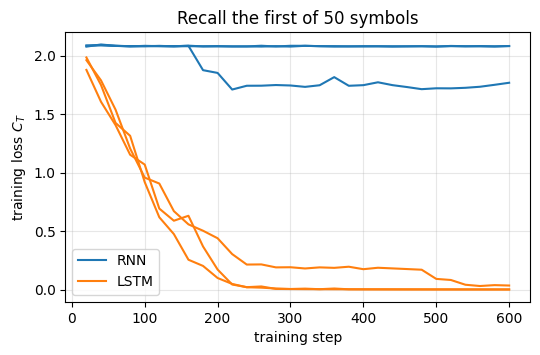

In [13]:
import time

import matplotlib.pyplot as plt
import torch.nn as nn
import torch.nn.functional as F


class RecallModel(nn.Module):
    """A recurrent cell followed by the linear output layer F, applied to the last hidden state: y_T = F(h_T)."""

    def __init__(self, cell_type, hidden_size=32):
        super().__init__()
        if cell_type == "RNN":
            self.cell = nn.RNN(N_SYMBOLS, hidden_size, bias=False, batch_first=True)
        else:
            self.cell = LectureLSTM(N_SYMBOLS, hidden_size)
        self.F = nn.Linear(hidden_size, N_SYMBOLS)

    def forward(self, x):
        hs, _ = self.cell(x)
        return self.F(hs[:, -1])


cpu = torch.device("cpu")  # these small, step-by-step models run faster on the CPU than on a GPU


def train_recall(cell_type, length, seed, steps=600):
    """Train a RecallModel on sequences of the given length. Returns the per-step losses and the test accuracy."""
    torch.manual_seed(seed)
    g = torch.Generator().manual_seed(seed)
    model = RecallModel(cell_type).to(cpu)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)  # Adam: a variant of gradient descent not covered in the lecture
    losses = []
    for step in range(steps):
        x, gt = make_recall_batch(64, length, g)
        loss = F.cross_entropy(model(x.to(cpu)), gt.to(cpu))  # C_T = Loss(y_T, GT)
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        losses.append(loss.item())
    x, gt = make_recall_batch(1000, length, g)
    with torch.no_grad():
        accuracy = (model(x.to(cpu)).argmax(dim=1) == gt.to(cpu)).float().mean().item()
    return losses, accuracy


LONG = 50
SEEDS = [0, 1, 2]
lstm_done = "LectureLSTM" in globals() and LectureLSTM(N_SYMBOLS, 4)(torch.zeros(1, 2, N_SYMBOLS))[0] is not None
cell_types = ("RNN", "LSTM") if lstm_done else ("RNN",)
if not lstm_done:
    print("Please run and complete Exercise 3.1 to train the LSTM as well; training only the vanilla RNN.")
print(f"T = {LONG}, guessing gives a test accuracy of {1 / N_SYMBOLS:.3f}")
start = time.time()
results = {}
for cell_type in cell_types:
    for seed in SEEDS:
        results[(cell_type, seed)] = train_recall(cell_type, LONG, seed)
        print(f"{cell_type:4s} seed {seed}: test accuracy {results[(cell_type, seed)][1]:.2f}   ({time.time() - start:.1f} s)")

plt.figure(figsize=(6, 3.5))
for (cell_type, seed), (losses, _) in results.items():
    smooth = torch.tensor(losses).view(-1, 20).mean(dim=1)  # mean over blocks of 20 steps
    plt.plot(range(20, len(losses) + 1, 20), smooth, color="C0" if cell_type == "RNN" else "C1",
             label=cell_type if seed == SEEDS[0] else None)
plt.xlabel("training step")
plt.ylabel("training loss $C_T$")
plt.title(f"Recall the first of {LONG} symbols")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In our run the vanilla RNN's test accuracy stays near guessing (0.22, 0.12 and 0.12, where guessing gives 0.125), and its training loss stays far above the LSTM's, while the LSTM reaches 1.00, 1.00 and 0.98 in all three runs here. Your numbers may differ from ours, depending on your machine and PyTorch version.

The vanilla RNN usually stays near guessing, although on some machines or seeds it does learn the task. When preparing the notebook we repeated this with 10 seeds on one machine: the vanilla RNN stayed at or below 0.22 in 8 of them (the other two reached 0.44 and 1.00), and on another machine seed 0 reached 1.00. The LSTM reached at least 0.87 in all 10 of those runs, but it can occasionally get stuck as well. The overall pattern is consistent with the lecture's "Result: long-term temporal dependencies are inaccessible" for the vanilla RNN: with $T = 5$ in Section 2.3 the same kind of RNN learned the task every time.

### **3.3 Gradient Flow**

The lecture writes the gradient of the loss at step $t$ with respect to $h_1$ as a product over all the steps in between:

$$\frac{\partial C_t}{\partial h_1} = \frac{\partial C_t}{\partial y_t}\,\frac{\partial y_t}{\partial h_t}\,\frac{\partial h_t}{\partial h_{t-1}} \cdots \frac{\partial h_2}{\partial h_1}.$$

For the vanilla RNN, the gradients exponentially decay toward zero (vanish) when $\lambda_1 < 1/\gamma$, where $\lambda_1$ is the largest singular value of the weights and $\gamma = 1$ for tanh; when $\lambda_1 > 1/\gamma$ they can grow instead (explode). In the scalar cell on the problem sheet, each factor is $\partial h_t/\partial h_{t-1} = (1 - h_t^2)\,w$, with the recurrent weight $w$ in the role of $\lambda_1$. For vectors, the weights that multiply $h_{t-1}$ are the block $W_h$ of $W$ (problem sheet), so we look at the largest singular value of $W_h$ as well as of $W$. For the LSTM, the lecture says that instead of computing the new state as a matrix product with the old state, it computes the difference between them, creating a "Constant Error Carousel" which ensures that gradients don't decay.

The cell below measures, for untrained models, how much the loss at the last step $C_T$ depends on the first input $x_1$: the norm of $\partial C_T / \partial x_1$, which reaches $x_1$ through $h_1$ (and, in the LSTM, through $c_1$). It is averaged over 5 random sequences for each length $T$. The four models are:
- a vanilla RNN as initialised by PyTorch, like the RNNs at the start of training in Section 3.2;
- the same RNN with $W_h$ rescaled to $\lambda_1 = 0.9$ (below $1/\gamma = 1$);
- the same RNN with $W_h$ rescaled to $\lambda_1 = 3$ (above $1/\gamma$);
- your LSTM from Exercise 3.1, as initialised by PyTorch (only if the exercise is complete).

It runs on the CPU in double precision (`float64`, which MPS does not support), because the smallest values are too small for `float32`.

RNN as initialised by PyTorch: lambda1(W) = 1.24, lambda1(W_h) = 1.13



   T      RNN, PyTorch init  RNN, lambda1(W_h)=0.9    RNN, lambda1(W_h)=3         LSTM (lecture)
   1               1.84e-01               1.32e-01               1.51e-01               3.49e-02
   2               9.59e-02               8.07e-02               2.37e-01               3.18e-02
   5               1.38e-02               7.59e-03               5.49e-01               3.22e-02
  10               1.77e-03               1.35e-04               1.08e+00               4.34e-02
  20               2.66e-06               6.08e-08               1.94e+00               1.06e-01
  50               5.05e-13               7.15e-18               2.86e+00               3.14e-01
 100               1.95e-24               7.35e-34               1.25e+03               7.45e-01


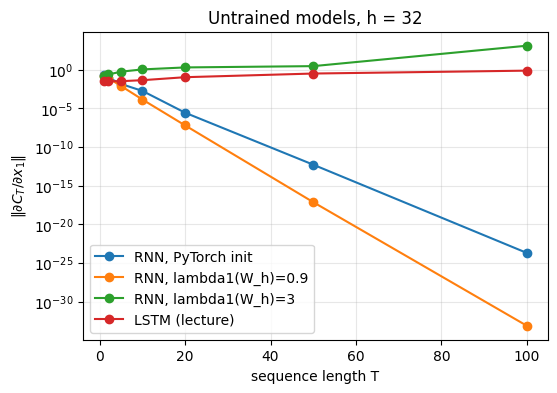

In [14]:
import copy

import matplotlib.pyplot as plt
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(SEED)
hidden = 32
lengths = [1, 2, 5, 10, 20, 50, 100]


def lambda1(matrix):
    """Largest singular value."""
    return torch.linalg.matrix_norm(matrix, ord=2).item()


def rnn_with_lambda1(base, target):
    """A copy of the RNN `base` whose W_h (weight_hh_l0) is rescaled to have the largest singular value `target`."""
    rnn = copy.deepcopy(base)
    with torch.no_grad():
        rnn.weight_hh_l0 *= target / lambda1(rnn.weight_hh_l0)
    return rnn


base_rnn = nn.RNN(N_SYMBOLS, hidden, bias=False, batch_first=True).double()
W = torch.cat([base_rnn.weight_ih_l0, base_rnn.weight_hh_l0], dim=1)
print(f"RNN as initialised by PyTorch: lambda1(W) = {lambda1(W):.2f}, lambda1(W_h) = {lambda1(base_rnn.weight_hh_l0):.2f}\n")
models = {
    "RNN, PyTorch init": base_rnn,
    "RNN, lambda1(W_h)=0.9": rnn_with_lambda1(base_rnn, 0.9),
    "RNN, lambda1(W_h)=3": rnn_with_lambda1(base_rnn, 3.0),
}
lstm = LectureLSTM(N_SYMBOLS, hidden).double() if "LectureLSTM" in globals() else None
if lstm is not None and lstm(torch.zeros(1, 2, N_SYMBOLS, dtype=torch.float64))[0] is not None:
    models["LSTM (lecture)"] = lstm
else:
    print("Please run and complete Exercise 3.1 to include the LSTM; showing the vanilla RNNs only.\n")
F_out = nn.Linear(hidden, N_SYMBOLS).double()  # the same output layer F for all models


def grad_first_input(cell, T, n_sequences=5):
    """Mean norm of dC_T/dx_1 over random sequences of length T."""
    norms = []
    for _ in range(n_sequences):
        x, gt = make_recall_batch(1, T)
        x = x.double().requires_grad_()
        hs, _ = cell(x)
        loss = F.cross_entropy(F_out(hs[:, -1]), gt)  # C_T
        (grad,) = torch.autograd.grad(loss, x)
        norms.append(grad[0, 0].norm().item())  # gradient with respect to x_1
    return sum(norms) / n_sequences


results_grad = {name: [grad_first_input(cell, T) for T in lengths] for name, cell in models.items()}

print(f"{'T':>4} " + " ".join(f"{name:>22}" for name in results_grad))
for i, T in enumerate(lengths):
    print(f"{T:>4} " + " ".join(f"{results_grad[name][i]:>22.2e}" for name in results_grad))

plt.figure(figsize=(6, 4))
for name, norms in results_grad.items():
    plt.semilogy(lengths, norms, "o-", label=name)
plt.xlabel("sequence length T")
plt.ylabel(r"$\|\partial C_T / \partial x_1\|$")
plt.title("Untrained models, h = 32")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

In our run, the RNN as initialised by PyTorch has $\lambda_1(W_h) = 1.13$ (and $\lambda_1(W) = 1.24$), both above $1/\gamma = 1$, yet its gradient decays exponentially (a straight line on the log scale), from about $2 \times 10^{-1}$ at $T = 1$ to about $2 \times 10^{-24}$ at $T = 100$. So $\lambda_1 < 1/\gamma$ is enough for the gradient to vanish, but not necessary: each factor $\partial h_k/\partial h_{k-1}$ also contains the derivative of tanh, as in the scalar case on the problem sheet, $(1 - h_t^2)\,w$ with $0 < 1 - h_t^2 \le 1$, which shrinks the product further. This is how the RNNs in Section 3.2 start training: the loss at the last step hardly depends on the first input.

- With $\lambda_1(W_h) = 0.9$, the lecture's vanishing case, the gradient decays even faster, to below $10^{-33}$ at $T = 100$. (In `float32` both RNN values at $T = 100$ come out as exactly 0.)
- With $\lambda_1(W_h) = 3$, the gradient grows instead (explodes): from about 0.15 at $T = 1$ to about $10^3$ at $T = 100$.
- The lecture's LSTM keeps the gradient: it grows from about 0.03 to about 0.7, in line with the lecture's "Constant Error Carousel".

When preparing the notebook we repeated this for 6 seeds. The PyTorch initialisation always had $\lambda_1(W_h)$ between 1.01 and 1.19 and a gradient below $10^{-19}$ at $T = 100$. With $\lambda_1(W_h) = 3$ the gradient at $T = 100$ was always larger than at $T = 1$, but by very different factors (from about 3 to about $2 \times 10^4$). The LSTM's gradient at $T = 100$ was always larger than at $T = 1$.

These are untrained models on random inputs. They show why the gradient signal from $C_T$ hardly reaches the first input in a vanilla RNN, and why it does in the LSTM; they do not predict exactly what happens during training.

## Summary

- A convolution layer slides each of its $C_{\text{out}}$ filters over the input, multiplies element-wise with every $C_{\text{in}} \times K \times K$ window, sums, and adds one bias per filter. Its output is $C_{\text{out}} \times H' \times W'$ with $H' = (H - K + 2P)/S + 1$ and $W' = (W - K + 2P)/S + 1$, and PyTorch stores batches as $N \times C \times H \times W$.
- The lecture's RNN cell is $h_t = \tanh W \begin{pmatrix} x_t \\ h_{t-1} \end{pmatrix}$ with $W = [\,W_x \;\; W_h\,]$; `nn.RNN(d, h, bias=False)` stores the two blocks and has $h(d + h)$ parameters. The outputs are $y_t = F(h_t)$ and the losses $C_t = \text{Loss}(y_t, \text{GT}_t)$.
- Training runs backward through the unfolded network and sums the gradients of the copies of $W$. In a vanilla RNN, $\partial C_t / \partial h_1$ is a product of one factor $\partial h_k / \partial h_{k-1}$ per step, so it vanishes when $\lambda_1 < 1/\gamma$ and can explode when $\lambda_1 > 1/\gamma$. The tanh derivative in each factor can make it vanish even when $\lambda_1 > 1/\gamma$ (Section 3.3). Norm clipping mitigates exploding gradients.
- The LSTM's memory cell $c_t = c_{t-1} + \dots$ is the lecture's "Constant Error Carousel", which ensures that gradients don't decay. In Section 3.2 the LSTM learned to recall a symbol over 50 steps in all three runs here, while the vanilla RNN usually stays near guessing; the results vary between runs and machines.